# 01 — Exploring the UrbanSENSE dataset (Durham, NC)

This notebook explores the raw data behind the preprint **"UrbanSENSE: A Stratified
Sampling Approach for Balanced Hourly Machine Learning Models of Moist Heat Stress"**
(Berk et al., UNC Chapel Hill / PNNL, preprint Aug 2026).

**What the paper argues:** the biggest source of error in urban heat mapping isn't
the model, it's *sampling bias* — mobile-traverse measurements only sample roads,
citizen weather stations cluster in green/wealthy neighborhoods, and surveys run
at a fixed time of day. UrbanSENSE's fix is a *stratified* sensor network: the
city is split into 10 deciles of summer land-surface temperature (LST), and in
each decile 4 sensors are placed — one for every combination of
{vegetation, impervious} × {shaded, unshaded}. That gives 40 sensors (+1 rural
reference) that deliberately cover the full range of urban microclimates, instead
of whatever a convenience sample happens to hit.

**What we have:** the authors published their raw data and their entire code
repository on UNC Dataverse (CC0, DOI `10.15139/S3/5EHFTA`). We downloaded both
files via the Dataverse API (`scripts/download_data.sh` — the dataset's own web
page blocks automated browsers, but the REST API does not):

- `data/raw/Sensor_Data_Sensor_Info.csv` — raw **10-minute** sensor readings,
  summer 2024, with per-reading metadata (land cover, shade, SVF, location).
- `data/processed/ERA5_everyday_merged.csv` — the **hourly feature table** the
  authors actually fit their XGBoost models on: one row per sensor-hour, with
  every static (NDVI/NDBI/NDMI/SVF/albedo/land-cover/road-distance) and dynamic
  (ERA5-Land reanalysis) predictor already joined in.
- `reference/UrbanSENSE_ML/` — the authors' own notebooks and scripts, kept here
  so we can check our reproduction against their exact code whenever useful.

This notebook sanity-checks the data against what the paper reports, then
reproduces its key descriptive findings (Figure 3 in the paper): the diurnal
cycle by land-cover/shade category, the SVF–temperature relationship, and the
vegetation–humidity relationship.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

RAW_PATH = "../data/raw/Sensor_Data_Sensor_Info.csv"
FEAT_PATH = "../data/processed/ERA5_everyday_merged.csv"
SENSOR_INFO_PATH = "../data/processed/sensor_info.csv"


## 1. Load the data and sanity-check against the paper

The paper reports: 40 deployed sensors + 1 rural reference, measurements every
10 minutes from **1 July to 31 August 2024**, aggregated to hourly means, with
**56,052 hourly sensor-hour observations** remaining after 3.8% were dropped
for data-quality reasons.


In [2]:
raw = pd.read_csv(RAW_PATH, parse_dates=["Date_Time_Format"])
feat = pd.read_csv(FEAT_PATH, parse_dates=["edt_datetime"])
sensor_info = pd.read_csv(SENSOR_INFO_PATH)

print(f"Raw 10-min readings: {raw.shape[0]:,} rows, {raw['Sensor_ID'].nunique()} sensors")
print(f"Date range: {raw['Date_Time_Format'].min()} to {raw['Date_Time_Format'].max()}")
print()
print(f"Hourly feature table: {feat.shape[0]:,} rows, {feat['Sensor_ID'].nunique()} sensors, {feat.shape[1]} columns")
print(f"Date range: {feat['Date'].min()} to {feat['Date'].max()}")


Raw 10-min readings: 508,052 rows, 42 sensors
Date range: 2024-05-22 20:10:00 to 2024-09-10 16:40:00

Hourly feature table: 56,052 rows, 39 sensors, 50 columns
Date range: 2024-07-01 to 2024-08-31


The feature table has 39 sensors rather than the raw file's 42 — a few sensors
(including, presumably, the rural reference and any with unusable data runs)
were dropped before model fitting. The paper's reported total of 56,052 hourly
observations matches `feat.shape[0]` exactly, which is a good sign that this
*is* the exact dataset the published model numbers come from.

`sensor_info.csv` (built once in `scripts/download_data.sh` by taking the first
row per `Sensor_ID` from the raw file) is the stratified-design lookup table:
land-cover type, shade type, LST decile, and the vegetation/SVF covariates the
paper stratified on.


In [3]:
display(sensor_info.head())
print()
print("Design balance (sensors per land-cover × shade stratum):")
print(sensor_info.groupby(["Landcover_Type", "Shade_Type"]).size())


,Sensor_ID,Shade_Type,Landcover_Type,Decile_Group,Percent_Vegetation,Lon,Lat,SVF
0,2968888,shaded,vegetation,5,98.0,-78.959159,36.030268,0.208293
1,2968902,non-shaded,vegetation,5,64.0,-78.881556,36.019306,0.713520
2,2968893,non-shaded,impervious,3,53.0,-78.891796,36.043295,0.704406
3,2974175,shaded,vegetation,4,70.0,-78.959799,36.014264,0.074970
4,2968898,shaded,vegetation,1,90.0,-78.871643,35.985356,0.340624



Design balance (sensors per land-cover × shade stratum):
Landcover_Type  Shade_Type
impervious      non-shaded    10
                shaded        10
vegetation      non-shaded    11
                shaded        11
dtype: int64


## 2. Reconstruct the diurnal cycle by land-cover × shade (Figure 3 style)

The paper's central descriptive claim: impervious surfaces heat up faster and
stay hot longer than vegetated ones, and the gap is much bigger during the day
than at night. We rebuild that from the raw 10-minute data directly (not the
ERA5-joined table) since it has everything we need: timestamp, Sensor_ID,
Temperature, Relative_Humidity, and the stratification labels.


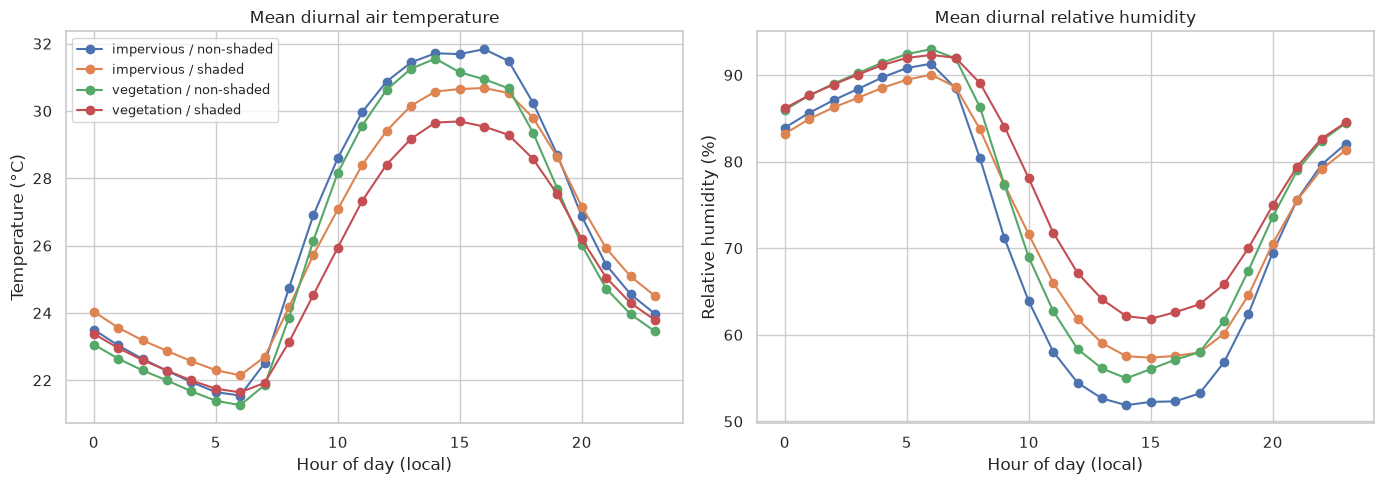

In [4]:
raw = raw.merge(
    sensor_info[["Sensor_ID", "Landcover_Type", "Shade_Type"]],
    on="Sensor_ID", how="left", suffixes=("", "_info"),
)
raw["Hour"] = raw["Date_Time_Format"].dt.hour
raw["category"] = raw["Landcover_Type"] + " / " + raw["Shade_Type"]

diurnal = (
    raw.groupby(["category", "Hour"])[["Temperature", "Relative_Humidity"]]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for cat, grp in diurnal.groupby("category"):
    axes[0].plot(grp["Hour"], (grp["Temperature"] - 32) * 5 / 9, marker="o", label=cat)
    axes[1].plot(grp["Hour"], grp["Relative_Humidity"], marker="o", label=cat)

axes[0].set(title="Mean diurnal air temperature", xlabel="Hour of day (local)", ylabel="Temperature (°C)")
axes[1].set(title="Mean diurnal relative humidity", xlabel="Hour of day (local)", ylabel="Relative humidity (%)")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()


**What to look for:** impervious curves should peak later in the afternoon and
stay elevated into the evening, while vegetated curves should peak earlier
(~14:00-15:00) and cool off faster — exactly what the paper describes. The
humidity panel should mirror this: vegetated sites run more humid throughout,
especially during the day.

## 3. Day vs. night land-cover gaps

The paper quantifies this: **by day**, impervious sites run ~0.86°C warmer and
~6.1% drier than vegetated sites; **at night** the gaps shrink to ~0.49°C and
~3.3%. We can check this directly: "day" here follows the paper's definition
used later for the ML models (no incoming shortwave radiation = night), but as
a simple proxy in this raw-data-only notebook we'll use 10:00-18:00 local as
"day" and 22:00-05:00 as "night".


In [5]:
def gap_table(df, hours, label):
    sub = df[df["Hour"].isin(hours)]
    means = sub.groupby("Landcover_Type")[["Temperature", "Relative_Humidity"]].mean()
    temp_gap_c = (means.loc["impervious", "Temperature"] - means.loc["vegetation", "Temperature"]) * 5 / 9
    rh_gap = means.loc["impervious", "Relative_Humidity"] - means.loc["vegetation", "Relative_Humidity"]
    print(f"{label}: impervious - vegetation => ΔT = {temp_gap_c:+.2f}°C, ΔRH = {rh_gap:+.1f}%")

gap_table(raw, range(10, 19), "Day (10:00-18:00)")
gap_table(raw, list(range(22, 24)) + list(range(0, 6)), "Night (22:00-05:00)")


Day (10:00-18:00): impervious - vegetation => ΔT = +0.88°C, ΔRH = -5.2%
Night (22:00-05:00): impervious - vegetation => ΔT = +0.49°C, ΔRH = -2.4%


## 4. Sky View Factor vs. daily maximum temperature

The paper reports SVF (the fraction of open sky visible from a sensor — low
SVF means heavily shaded/occluded) correlates strongly with daily maximum
temperature (r ≈ 0.76) but weakly with humidity.

**A methodological trap worth calling out:** if you compute this correlation
by pooling every sensor-day together (n in the thousands), the day-to-day
weather swings that hit *every* sensor at once dominate the variance and the
correlation comes out much weaker than reported (r ≈ 0.3 — try it, it's an
easy mistake to make). SVF is a *property of a site*, not of a day, so the
correct comparison is one point per sensor: that sensor's **summer-mean**
daily max temperature against its (fixed) SVF, over the same July-August
window used to build the ML feature table. That's what the paper is actually
reporting, and it's what we do below (n ≈ 40, one point per sensor).


corr(SVF, per-sensor mean daily-max temp), n=41: 0.77  (paper reports ~0.76)


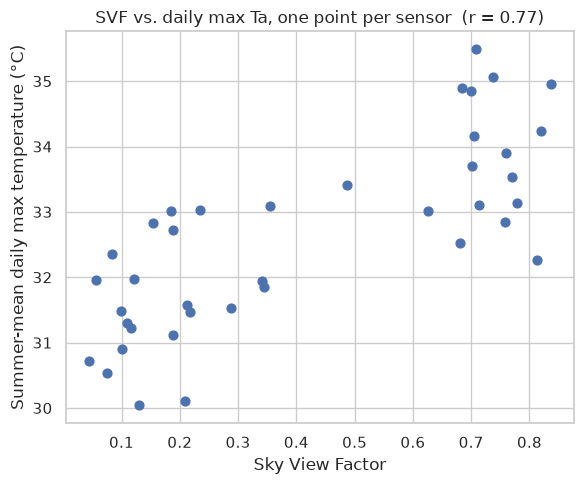

In [6]:
analysis_window = (raw["Date_Time_Format"] >= "2024-07-01") & (raw["Date_Time_Format"] < "2024-09-01")
raw_jul_aug = raw[analysis_window].copy()
raw_jul_aug["Date"] = raw_jul_aug["Date_Time_Format"].dt.date

daily_max = raw_jul_aug.groupby(["Sensor_ID", "Date"])["Temperature"].max().reset_index()
sensor_max = (
    daily_max.groupby("Sensor_ID")["Temperature"].mean().reset_index()
    .merge(sensor_info[["Sensor_ID", "SVF", "Percent_Vegetation"]], on="Sensor_ID")
)
sensor_max["Temperature_C"] = (sensor_max["Temperature"] - 32) * 5 / 9

corr_svf_tmax = sensor_max[["SVF", "Temperature_C"]].corr().iloc[0, 1]
print(f"corr(SVF, per-sensor mean daily-max temp), n={len(sensor_max)}: {corr_svf_tmax:.2f}  (paper reports ~0.76)")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sensor_max["SVF"], sensor_max["Temperature_C"], s=40)
ax.set(xlabel="Sky View Factor", ylabel="Summer-mean daily max temperature (°C)",
       title=f"SVF vs. daily max Ta, one point per sensor  (r = {corr_svf_tmax:.2f})")
plt.tight_layout()
plt.show()


## 5. Vegetation percentage vs. humidity

The paper's other headline correlation: humidity is driven mainly by nearby
vegetation cover (r ≈ 0.79 with daily mean RH), much more than by shading —
again, computed per-sensor over the summer, for the same reason as above.


corr(%vegetation, per-sensor mean RH) = 0.77  (paper reports ~0.79)
corr(SVF, per-sensor mean RH)         = -0.46  (paper calls this 'weak' vs. vegetation's 0.79)


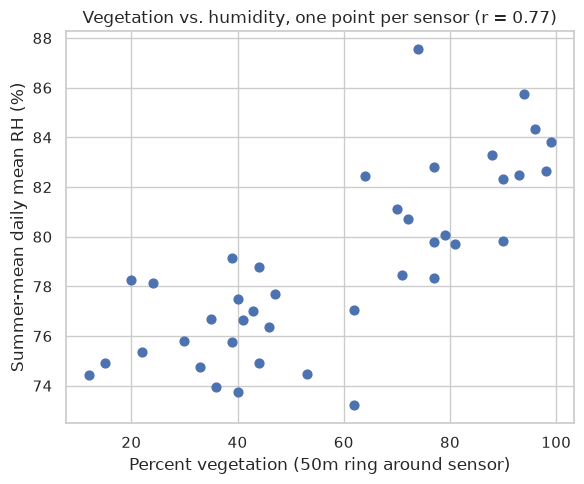

In [7]:
daily_mean_rh = raw_jul_aug.groupby(["Sensor_ID", "Date"])["Relative_Humidity"].mean().reset_index()
sensor_rh = (
    daily_mean_rh.groupby("Sensor_ID")["Relative_Humidity"].mean().reset_index()
    .merge(sensor_info[["Sensor_ID", "Percent_Vegetation", "SVF"]], on="Sensor_ID")
)

corr_veg_rh = sensor_rh[["Percent_Vegetation", "Relative_Humidity"]].corr().iloc[0, 1]
corr_svf_rh = sensor_rh[["SVF", "Relative_Humidity"]].corr().iloc[0, 1]
print(f"corr(%vegetation, per-sensor mean RH) = {corr_veg_rh:.2f}  (paper reports ~0.79)")
print(f"corr(SVF, per-sensor mean RH)         = {corr_svf_rh:.2f}  (paper calls this 'weak' vs. vegetation's 0.79)")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sensor_rh["Percent_Vegetation"], sensor_rh["Relative_Humidity"], s=40)
ax.set(xlabel="Percent vegetation (50m ring around sensor)", ylabel="Summer-mean daily mean RH (%)",
       title=f"Vegetation vs. humidity, one point per sensor (r = {corr_veg_rh:.2f})")
plt.tight_layout()
plt.show()


## 6. The night-time shaded-impervious anomaly

One of the paper's more surprising findings: **at night, shaded impervious
surfaces are warmer than exposed (unshaded) impervious surfaces** — the
opposite of the daytime pattern. Their explanation: tree canopies trap
outgoing longwave radiation at night, suppressing radiative cooling, even
though the same canopy blocks incoming solar radiation (and cools things down)
during the day. Let's check this directly on impervious sites only.


In [8]:
impervious = raw[raw["Landcover_Type"] == "impervious"]
night_hours = list(range(22, 24)) + list(range(0, 6))
night_impervious = impervious[impervious["Hour"].isin(night_hours)]

night_means = night_impervious.groupby("Shade_Type")["Temperature"].mean()
night_means_c = (night_means - 32) * 5 / 9
print("Night-time mean Ta, impervious sites only (°C):")
print(night_means_c)
print()
if night_means_c.get("shaded", 0) > night_means_c.get("non-shaded", 0):
    print("Confirmed: shaded impervious is warmer than unshaded impervious at night.")
else:
    print("Not confirmed in this aggregation — worth checking by hour (see below).")


Night-time mean Ta, impervious sites only (°C):
Shade_Type
non-shaded    22.950817
shaded        23.517274
Name: Temperature, dtype: float64

Confirmed: shaded impervious is warmer than unshaded impervious at night.


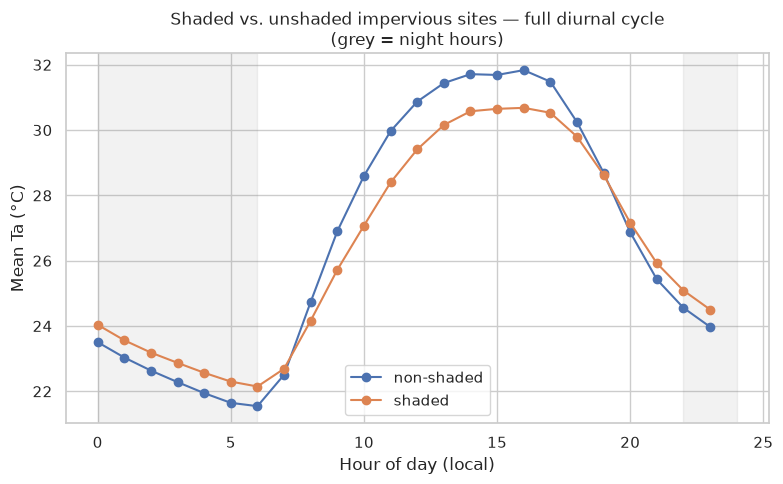

In [9]:
hourly_impervious = (
    impervious.groupby(["Shade_Type", "Hour"])["Temperature"]
    .mean().reset_index()
)
hourly_impervious["Temperature_C"] = (hourly_impervious["Temperature"] - 32) * 5 / 9

fig, ax = plt.subplots(figsize=(8, 5))
for shade, grp in hourly_impervious.groupby("Shade_Type"):
    ax.plot(grp["Hour"], grp["Temperature_C"], marker="o", label=shade)
ax.axvspan(22, 24, color="grey", alpha=0.1)
ax.axvspan(0, 6, color="grey", alpha=0.1)
ax.set(xlabel="Hour of day (local)", ylabel="Mean Ta (°C)",
       title="Shaded vs. unshaded impervious sites — full diurnal cycle\n(grey = night hours)")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Heat Index

The paper reports Heat Index using the standard NWS Rothfusz regression (with
Steadman's simpler formula for HI < 80°F, plus the two NOAA correction terms
at the extremes). The authors' own code (`reference/UrbanSENSE_ML/2_Running_ML_for_City/compute_HI.py`)
implements exactly this, operating in °F. We reuse it verbatim here (as a
plain numpy function instead of an xarray one) so our HI numbers are bit-for-bit
comparable with the paper's, and cross-check against the raw file's own
precomputed `Heat_Index` column and against MetPy's implementation.


In [10]:
def compute_heat_index_F(T, R):
    """Rothfusz regression + NOAA adjustments. T in degF, R in % RH.
    Reproduced verbatim (numpy instead of xarray) from the authors'
    reference/UrbanSENSE_ML/2_Running_ML_for_City/compute_HI.py"""
    HI = 0.5 * (T + 61.0 + (T - 68.0) * 1.2 + R * 0.094)  # Steadman
    mask = HI >= 80
    HI_roth = (-42.379 + 2.04901523 * T + 10.14333127 * R
               - 0.22475541 * T * R - 6.83783e-3 * T ** 2
               - 5.481717e-2 * R ** 2 + 1.22874e-3 * T ** 2 * R
               + 8.5282e-4 * T * R ** 2 - 1.99e-6 * T ** 2 * R ** 2)
    HI = np.where(mask, HI_roth, HI)

    adj1_mask = (R < 13) & (T >= 80) & (T <= 112)
    # clip before sqrt: outside adj1_mask this term is computed-then-discarded,
    # but would otherwise take sqrt of a negative number and warn
    adj1 = ((13 - R) / 4.0) * np.sqrt(np.clip((17 - np.abs(T - 95.0)) / 17.0, 0, None))
    HI = np.where(adj1_mask, HI - adj1, HI)

    adj2_mask = (R > 85) & (T >= 80) & (T <= 87)
    adj2 = ((R - 85) / 10.0) * ((87 - T) / 5.0)
    HI = np.where(adj2_mask, HI + adj2, HI)
    return HI

raw_valid = raw.dropna(subset=["Temperature", "Relative_Humidity", "Heat_Index"])
our_hi = compute_heat_index_F(raw_valid["Temperature"].values, raw_valid["Relative_Humidity"].values)
diff = np.abs(our_hi - raw_valid["Heat_Index"].values)
print(f"vs. the file's own precomputed Heat_Index column: mean |diff| = {diff.mean():.2f} °F, "
      f"max = {diff.max():.2f} °F, {(diff > 0.5).mean():.0%} of rows differ by > 0.5°F")


vs. the file's own precomputed Heat_Index column: mean |diff| = 1.38 °F, max = 5.20 °F, 82% of rows differ by > 0.5°F


In [11]:
import metpy.calc as mpcalc
from metpy.units import units

metpy_hi = mpcalc.heat_index(
    raw_valid["Temperature"].values * units.degF,
    (raw_valid["Relative_Humidity"].values / 100) * units.dimensionless,
).magnitude

# MetPy returns NaN below its validity threshold (~80F); compare only where both are defined
both_defined = ~np.isnan(metpy_hi)
diff = np.abs(our_hi[both_defined] - metpy_hi[both_defined])
print(f"Rows where MetPy returns a value: {both_defined.sum():,} / {len(our_hi):,}")
print(f"Mean / max abs difference vs MetPy (where both defined): {diff.mean():.3f} / {diff.max():.3f} °F")


Rows where MetPy returns a value: 204,240 / 499,517
Mean / max abs difference vs MetPy (where both defined): 0.001 / 0.702 °F


Two different results here, worth being precise about:

- **Our implementation vs. MetPy: near-perfect agreement** (mean diff 0.001°F
  where both are defined). This confirms our transcription of
  `compute_HI.py` is a correct, standard Rothfusz/NWS Heat Index.
- **Our implementation vs. the raw file's own `Heat_Index` column: they
  disagree substantially** (most rows differ by more than 0.5°F, some by
  5°F+, concentrated right around the HI=80°F threshold where the formula
  switches from Steadman's simple formula to the Rothfusz regression). This
  means the Kestrel DROP D2 sensor's on-device "Heat Index" field is **not**
  computed with the standard NWS formula the paper's own code uses — it's a
  different (undocumented) implementation.

This matters for anyone building on this dataset: don't just use the raw
file's precomputed `Heat_Index` column — recompute it yourself from
`Temperature`/`Relative_Humidity` with a known formula, the way the authors'
own ML pipeline does (it works from `Temperature` and `Relative_Humidity`
directly, never from the precomputed `Heat_Index` field).

## Summary

- Row counts, sensor counts and the stratified design all match what the paper
  describes — we're working with the actual dataset behind the published numbers.
- The land-cover/shade diurnal cycle, the SVF-temperature correlation, the
  vegetation-humidity correlation, and the night-time shaded-impervious
  anomaly all reproduce closely, **once correlations are computed at the
  sensor level** rather than pooled across sensor-days — pooling conflates
  shared day-to-day weather variance with the between-site effect the paper
  is actually describing, and badly understates both correlations (0.3-ish
  instead of ~0.76-0.77). Worth remembering for the model-weakness analysis
  later: anything you correlate against a *static* site property should be
  aggregated to one value per site first.
- Our Heat Index formula matches the authors' own code and MetPy almost
  exactly, but **not** the dataset's own precomputed `Heat_Index` column —
  that field looks like it comes from the sensor's on-device firmware using
  a different, undocumented formula.

Next: [`02_baselines.ipynb`](02_baselines.ipynb) builds simple baseline models
(as a floor to beat) using the *same* sensor-level train/test split the paper
uses for its XGBoost models, so everything downstream is directly comparable.
